# Aula 06 — Imputação e Normalização de Dados

**Ciência de Dados — IMD/UFRN**  
Ana Paula Evangelista Melo Freitas · Matrícula 20250041027

### Objetivo
> Nessa atividade a base de anúncios de alugurl de São Paulo é preparada para análise. Possuíndo 3 probnlemas comuns em dados reais, como valores faltando em algumas colunas, variáveis medidas em unidades muito diferentes e distribuições com poucos valores muito altos que distorcem a escala.
>
>Para cada problema é usado uma técnica diferente: imputação, escalonamento e transformações. Além de aplicar cada técnica, o objetivo é observar o que ela altera nos dados, porque nenhum tratamento deixa a base exatamente como era.
>
---

## 1. Preparando a base

Primeiro são carregadas as bibliotecas da aula: pandas e numpy para manipular a tabela, matplotlib e seaborn para os gráficos, scipy.stats para medir assimetria e aplicar transformações, e os escaladores do scikit-learn, que serão usados mais à frente.


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import (
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)

sns.set_theme(style="whitegrid")

# Paleta da atividade: rosa → roxo
ROSA = "#EC407A"
ROXO = "#7B1FA2"
degrade = sns.blend_palette(["#F48FB1", ROSA, ROXO], as_cmap=True)

def pintar_degrade(ax):
    """Pinta as barras de um gráfico em degradê do rosa ao roxo."""
    barras = ax.patches
    n = len(barras)
    for i, barra in enumerate(barras):
        barra.set_facecolor(degrade(i / max(n - 1, 1)))
        barra.set_edgecolor("white")

## 2. Carregando a base

Nesta etapa a base é lida e passa por uma limpeza inicial: os nomes das colunas são simplificados, os anúncios repetidos são descartados e é criada uma coluna que diz se o imóvel é casa ou apartamento.

In [18]:
column_names = {
    "parking spaces": "parking_spaces",
    "hoa (R$)": "hoa",
    "rent amount (R$)": "rent_amount",
    "property tax (R$)": "property_tax",
    "total (R$)": "total",
}

imoveis = (
    pd.read_csv("data/imoveis_sao_paulo.csv")
    .rename(columns=column_names)
    .drop_duplicates()
    .reset_index(drop=True)
    .assign(
        property_type=lambda df: np.where(df["floor"].isna(), "casa", "apartamento")
    )
)

print(imoveis.shape)
imoveis.head()

(29439, 15)


,bairro,zona,tier,area,rooms,parking_spaces,floor,total_floors,transit_distance_min,furniture,hoa,rent_amount,property_tax,total,property_type
0,Santo Amaro,Zona Sul,mid,119.0,3,0.0,11.0,15.0,3,not furnished,NaN,5050.0,590.25,6910.0,apartamento
1,Vila Mariana,Zona Sul,premium,97.9,3,1.0,15.0,25.0,10,not furnished,1072.0,5060.0,833.17,6970.0,apartamento
2,Ipiranga,Zona Sul,mid,45.5,1,0.0,1.0,15.0,27,furnished,520.0,2470.0,283.92,3280.0,apartamento
3,Raposo Tavares,Zona Oeste,mid,180.4,4,1.0,8.0,15.0,94,not furnished,2274.0,6270.0,775.17,9320.0,apartamento
4,Brooklin,Zona Sul,luxury,36.1,0,1.0,2.0,8.0,1,not furnished,570.0,2960.0,330.00,3860.0,apartamento


> Análise: Depois da limpeza, a base ficou com cerca de 29 mil anúncios. Trocar nomes como "rent amount (R$)" por `rent_amount` deixa o código mais limpo, e tirar as duplicatas evita que o mesmo imóvel seja contado mais de uma vez nas estatísticas. A coluna `property_type` usa a falta de andar para identificar casas, o que já mostra que essa lacuna tem um motivo e não é um simples esquecimento no cadastro.

## 3. Diagnóstico da base

Antes de mexer nos dados, é preciso entender o que está errado com eles. Para isso calculo três coisas: a porcentagem de valores vazios em algumas colunas, a mediana de variáveis com unidades diferentes e o limite do 1% mais caro de aluguel, usado só para enquadrar o histograma (nenhum dado é removido).

In [19]:
missing = imoveis[["hoa", "parking_spaces", "floor"]].isna().mean().mul(100)
scales = imoveis[["rooms", "area", "rent_amount"]].median()
limit = imoveis["rent_amount"].quantile(.99)

missing.round(2), scales

(hoa                1.72
 parking_spaces     1.01
 floor             15.00
 dtype: float64,
 rooms             2.0
 area             75.8
 rent_amount    2900.0
 dtype: float64)

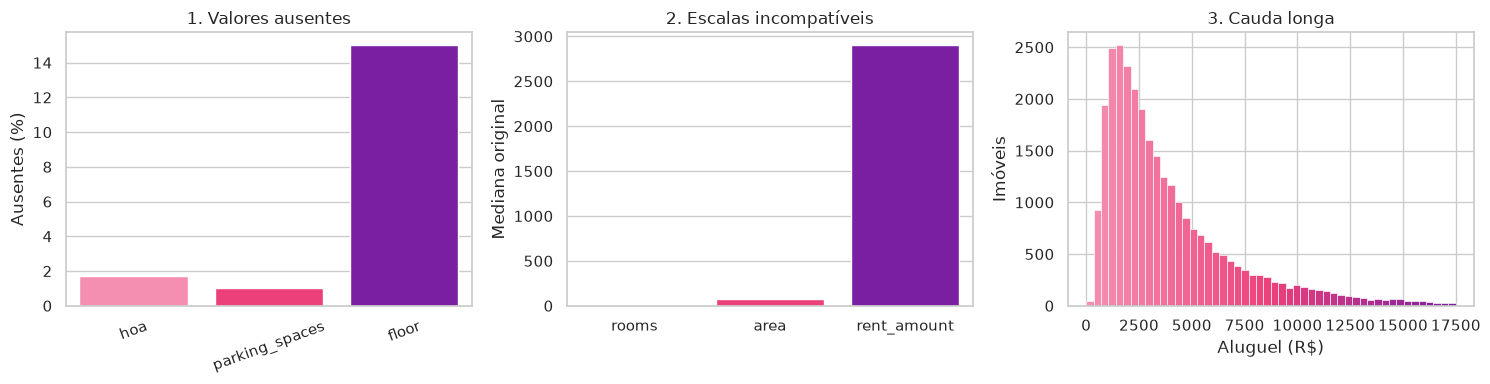

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(x=missing.index, y=missing.values, ax=axes[0], color=ROSA)
pintar_degrade(axes[0])
axes[0].set(title="1. Valores ausentes", ylabel="Ausentes (%)", xlabel="")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(x=scales.index, y=scales.values, ax=axes[1], color=ROSA)
pintar_degrade(axes[1])
axes[1].set(title="2. Escalas incompatíveis", ylabel="Mediana original", xlabel="")

sns.histplot(imoveis["rent_amount"], bins=50, binrange=(0, limit), ax=axes[2], color=ROSA)
pintar_degrade(axes[2])
axes[2].set(title="3. Cauda longa", xlabel="Aluguel (R$)", ylabel="Imóveis")

plt.tight_layout()
plt.show()

> Análise: O primeiro gráfico mostra que `hoa` e `parking_spaces` quase não têm lacunas (por volta de 2% e 1%), enquanto `floor` tem bem mais, cerca de 15%. Essa diferença chama atenção e indica que a falta de andar acontece por algum motivo específico.
>
> No segundo, as medianas são de 2 quartos, cerca de 76 m² e quase R$ 2.900 de aluguel. Como cada uma está numa unidade diferente, o aluguel parece enorme perto das outras só porque é medido em reais.
>
> No terceiro, a maioria dos aluguéis fica concentrada nos valores mais baixos e alguns poucos imóveis muito caros puxam a distribuição para a direita. Como a média fica acima da mediana, a assimetria é positiva.
>
> Com isso, a base tem três problemas para resolver: lacunas, unidades diferentes e cauda longa.

## 4. Ausência estrutural

Antes de preencher qualquer lacuna, vale perguntar por que ela existe. Aqui verifico se a falta de andar está ligada ao tipo de imóvel.

In [21]:
(
    imoveis
    .groupby("property_type")
    .agg(
        imoveis=("property_type", "size"),
        proporcao_sem_andar=("floor", lambda x: x.isna().mean()),
    )
)

,imoveis,proporcao_sem_andar
property_type,,
apartamento,25024,0.0
casa,4415,1.0


> Análise: De 4.415 casas, todas estão sem andar (proporção 1,0), e dos 25.024 apartamentos, nenhum está (proporção 0,0). Ou seja, floor não foi esquecido no cadastro: ele simplesmente não existe para casas. Isso é uma ausência estrutural. Se eu preenchesse com um número, estaria inventando um andar para um imóvel que não fica em prédio. Por isso a decisão é não imputar e deixar essa informação registrada em property_type.

## 5. Imputação

Numa lacuna real não dá para saber o valor certo, então não há como medir o erro da imputação. Para contornar isso, faço uma simulação: pego só os registros completos, apago alguns valores de propósito, preencho e depois comparo com o valor que eu já sabia.

In [23]:
# Semente fixa: o sorteio dá sempre o mesmo resultado
rng = np.random.default_rng(42)

# Apaga (vira NaN) uma fração aleatória dos valores de uma coluna
def erase_at_random(values, share):
    return values.mask(rng.random(len(values)) < share)

# Gabarito: só imóveis com hoa e vagas preenchidos
imoveis_true = (
    imoveis
    .dropna(subset=["hoa", "parking_spaces"])
    .reset_index(drop=True)
)

# Cópia com lacunas criadas de propósito em 3 tipos de variável
imoveis_missing = imoveis_true.assign(
    rooms=lambda df: erase_at_random(df["rooms"], .10),              # discreta
    rent_amount=lambda df: erase_at_random(df["rent_amount"], .15),  # contínua
    furniture=lambda df: erase_at_random(df["furniture"], .08),      # categórica
)

# Quantos valores foram apagados em cada coluna
(
    imoveis_missing[["rooms", "rent_amount", "furniture"]]
    .isna()
    .sum()
    .to_frame("ausentes")
    .assign(proporcao=lambda x: (x.ausentes / len(imoveis_missing)).round(3))
)

,ausentes,proporcao
rooms,2783,0.097
rent_amount,4308,0.150
furniture,2254,0.079


> Análise: Foram apagados 2.783 valores de quartos (9,7%), 4.308 aluguéis (15%) e 2.254 registros de mobília (7,9%). As proporções ficaram bem perto das que eu defini, mas não exatas, porque o sorteio é feito linha por linha. Como o apagamento foi totalmente aleatório, esse cenário é chamado de MCAR (ausência completamente aleatória). Agora tenho lacunas cujo valor verdadeiro eu conheço, o que vai permitir medir o erro de cada forma de preenchimento.

### 5.1 Média, mediana e mediana por tier

Testo três formas de preencher o aluguel: com a média geral, com a mediana geral e com a mediana de cada tier, que agrupa imóveis de padrão parecido.

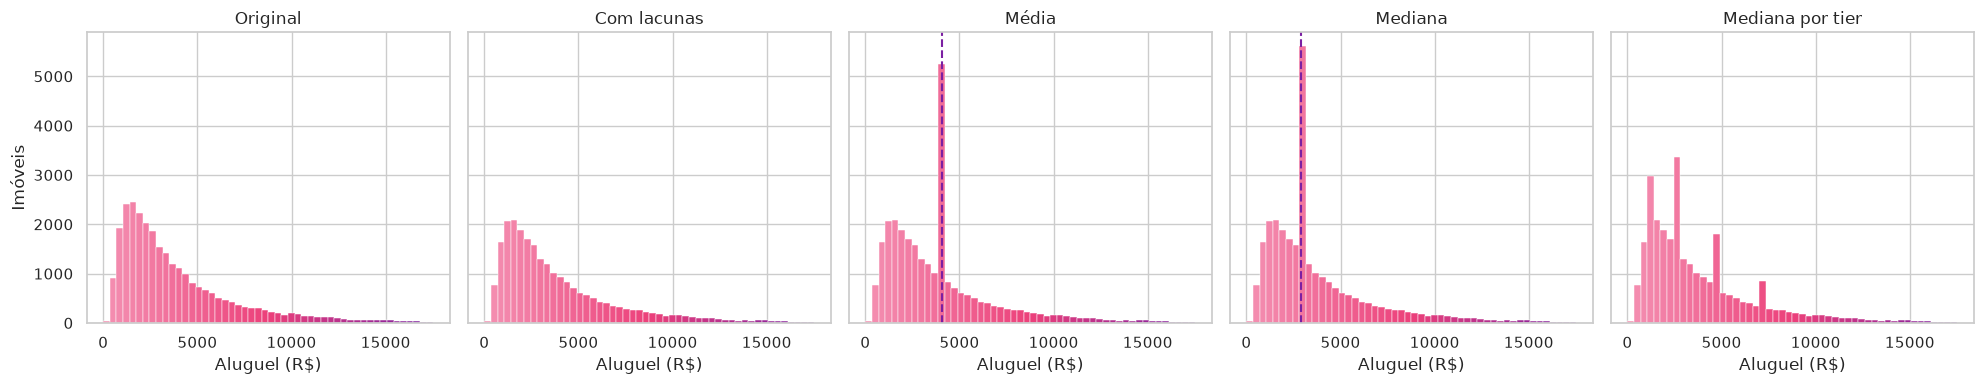

In [24]:
rent_mean = imoveis_missing.rent_amount.mean()
rent_median = imoveis_missing.rent_amount.median()

# Cada lacuna recebe a mediana do seu tier (se o tier não tiver dados, usa a mediana geral)
rent_group = (
    imoveis_missing
    .groupby("tier")
    .rent_amount
    .transform(lambda x: x.fillna(x.median()))
    .fillna(rent_median)
)

rent_versions = {
    "Original": imoveis_true.rent_amount,
    "Com lacunas": imoveis_missing.rent_amount,
    "Média": imoveis_missing.rent_amount.fillna(rent_mean),
    "Mediana": imoveis_missing.rent_amount.fillna(rent_median),
    "Mediana por tier": rent_group,
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
limit = imoveis_true.rent_amount.quantile(.99)

for ax, (label, values) in zip(axes, rent_versions.items()):
    sns.histplot(values.dropna(), bins=50, binrange=(0, limit), ax=ax, color=ROSA)
    pintar_degrade(ax)
    ax.set(title=label, xlabel="Aluguel (R$)", ylabel="Imóveis")
    # a linha tracejada marca o valor usado no preenchimento
    if label == "Média":
        ax.axvline(rent_mean, color=ROXO, linestyle="--")
    if label == "Mediana":
        ax.axvline(rent_median, color=ROXO, linestyle="--")

plt.tight_layout()
plt.show()

> Análise: Com a média e com a mediana, todas as lacunas recebem o mesmo número, o que cria uma barra muito alta num ponto só do histograma (onde está a linha tracejada) e deixa os dados menos espalhados do que realmente são. A média fica mais à direita porque os aluguéis muito caros puxam ela para cima. Já na mediana por tier, cada imóvel recebe o valor típico do seu grupo, então os preenchimentos se distribuem e o histograma fica mais parecido com o original.

### 5.2 Erro absoluto médio (MAE)

O histograma mostra a forma, mas não diz o quanto cada valor preenchido ficou longe do verdadeiro. Para isso uso o MAE: a média das diferenças, sem sinal, entre o valor real e o estimado. Calculo só nas posições apagadas, porque nas outras o erro seria zero e deixaria o resultado artificialmente baixo.

In [25]:
rent_missing = imoveis_missing.rent_amount.isna()
truth = imoveis_true.loc[rent_missing, "rent_amount"]

# MAE = média de |verdadeiro - imputado|, só nas posições apagadas
pd.Series(
    {
        "Média": (truth - rent_mean).abs().mean(),
        "Mediana": (truth - rent_median).abs().mean(),
        "Mediana por tier": (truth - rent_group[rent_missing]).abs().mean(),
    },
    name="MAE (R$)",
).round(2).to_frame()

,MAE (R$)
Média,2505.30
Mediana,2313.52
Mediana por tier,1820.84


> Análise: O erro médio foi de cerca de R$ 2.505 com a média, R$ 2.314 com a mediana e R$ 1.821 com a mediana por tier. A mediana erra menos que a média porque o aluguel é assimétrico e ela não é puxada pelos valores extremos. A mediana por tier foi a melhor porque leva em conta o padrão do imóvel. Esse resultado vale para lacunas aleatórias; se na base real faltassem mais os aluguéis caros, por exemplo, a conclusão poderia mudar.

### 5.3 Moda e variáveis discretas

Mobília é uma variável de categoria (mobiliado ou não), então média e mediana não fazem sentido. Nesse caso uso a moda, a categoria que mais aparece.

In [26]:
# .iloc[0] pega a primeira moda, caso haja empate
furniture_mode = imoveis_missing.furniture.mode().iloc[0]

pd.concat(
    {
        "Antes": imoveis_missing.furniture.value_counts(dropna=False),
        "Depois da moda": imoveis_missing.furniture.fillna(furniture_mode).value_counts(),
    },
    axis=1,
).fillna(0)

,Antes,Depois da moda
furniture,,
not furnished,17265,19519.0
furnished,9122,9122.0
NaN,2254,0.0


> Análise: A categoria mais comum é "not furnished". Ao preencher, as 2.254 lacunas foram todas para ela, que passou de 17.265 para 19.519 imóveis. Isso faz parecer que existem mais imóveis sem mobília do que realmente há.

Para o número de quartos, que é uma contagem, comparo média, mediana e moda.

In [27]:
pd.Series(
    {
        "média": imoveis_missing.rooms.mean(),
        "mediana": imoveis_missing.rooms.median(),
        "moda": imoveis_missing.rooms.mode().iloc[0],
    },
    name="quartos",
).to_frame()

,quartos
média,2.262085
mediana,2.000000
moda,2.000000


> Análise: A média deu cerca de 2,26 quartos, um número que não existe na prática. A mediana e a moda deram 2, um valor possível. Para contagens como essa, a mediana ou a moda fazem mais sentido.

**Resumo da imputação:** média para dados simétricos, mediana quando há valores extremos, moda para categorias e valor por grupo quando o grupo muda bastante o resultado. E sempre marcar quais valores foram preenchidos.

## 6. Escalonamento

Agora o problema é a diferença de unidades. Escalonar significa mudar a "régua" de uma variável: subtrair um centro e dividir por uma medida de escala. Aplico três escaladores ao aluguel e comparo o formato e a assimetria de cada resultado.

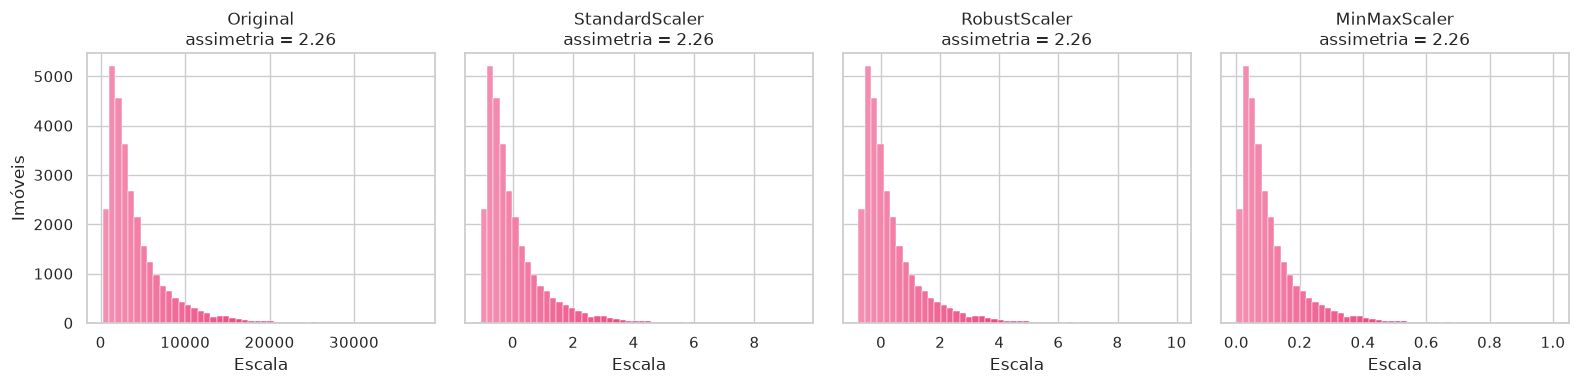

In [28]:
rent_frame = imoveis_true[["rent_amount"]]

# fit_transform calcula os parâmetros e já aplica
scaled = {
    "Original": rent_frame.rent_amount.to_numpy(),
    "StandardScaler": StandardScaler().fit_transform(rent_frame).ravel(),
    "RobustScaler": RobustScaler().fit_transform(rent_frame).ravel(),
    "MinMaxScaler": MinMaxScaler().fit_transform(rent_frame).ravel(),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

for ax, (label, values) in zip(axes, scaled.items()):
    sns.histplot(values, bins=50, ax=ax, color=ROSA)
    pintar_degrade(ax)
    ax.set(title=f"{label}\nassimetria = {stats.skew(values):.2f}", xlabel="Escala", ylabel="Imóveis")

plt.tight_layout()
plt.show()

> Análise: Os quatro histogramas têm o mesmo desenho e a mesma assimetria; só os números do eixo mudam. O StandardScaler coloca a média no zero, o RobustScaler coloca a mediana no zero e o MinMaxScaler espreme tudo entre 0 e 1. Isso acontece porque os três só deslocam e esticam o eixo, sem mudar a posição de um ponto em relação aos outros. A cauda longa continua lá.

### 6.1 Efeito de um valor extremo

Para ver como um valor muito alto afeta o MinMaxScaler, adiciono um aluguel inventado de R$ 500 mil, ajusto o escalador e depois tiro esse valor do resultado.

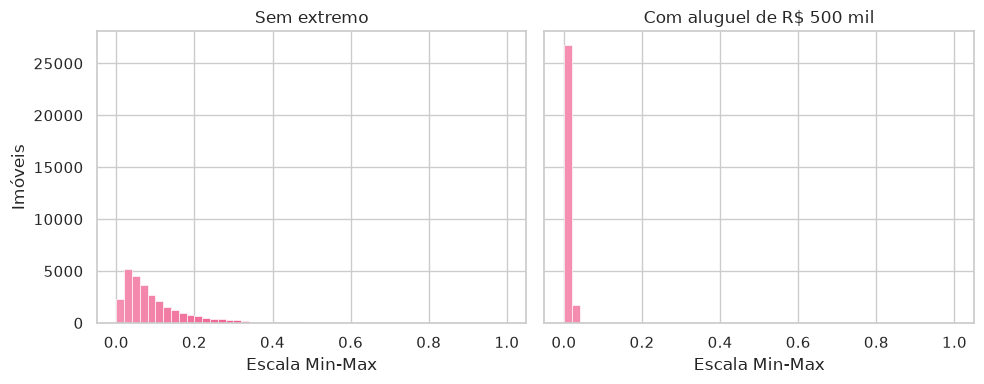

In [29]:
with_extreme = pd.concat(
    [rent_frame, pd.DataFrame({"rent_amount": [500_000.]})],
    ignore_index=True,
)

# [:-1] descarta o aluguel fictício depois do ajuste
minmax_extreme = MinMaxScaler().fit_transform(with_extreme).ravel()[:-1]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, values, title in zip(
    axes,
    [scaled["MinMaxScaler"], minmax_extreme],
    ["Sem extremo", "Com aluguel de R$ 500 mil"],
):
    sns.histplot(values, bins=50, binrange=(0, 1), ax=ax, color=ROSA)
    pintar_degrade(ax)
    ax.set(title=title, xlabel="Escala Min-Max", ylabel="Imóveis")

plt.tight_layout()
plt.show()

> Análise: Com o aluguel de R$ 500 mil, o máximo usado no cálculo cresce muito e quase todos os imóveis ficam amontoados perto do zero. Um único valor passou a definir a escala de toda a base. Por isso o MinMaxScaler só funciona bem sem extremos. Quando eles existem, o RobustScaler é mais confiável, já que a mediana e o IQR quase não mudam por causa de um ponto só.

**Conclusão:** escalonar deixa as variáveis comparáveis, mas não resolve a cauda longa.

## 7. Transformações

Como escalonar não muda a forma da distribuição, agora uso funções não lineares, que comprimem mais os valores altos do que os baixos. Para o aluguel, que é sempre positivo, comparo o log com o Box-Cox.

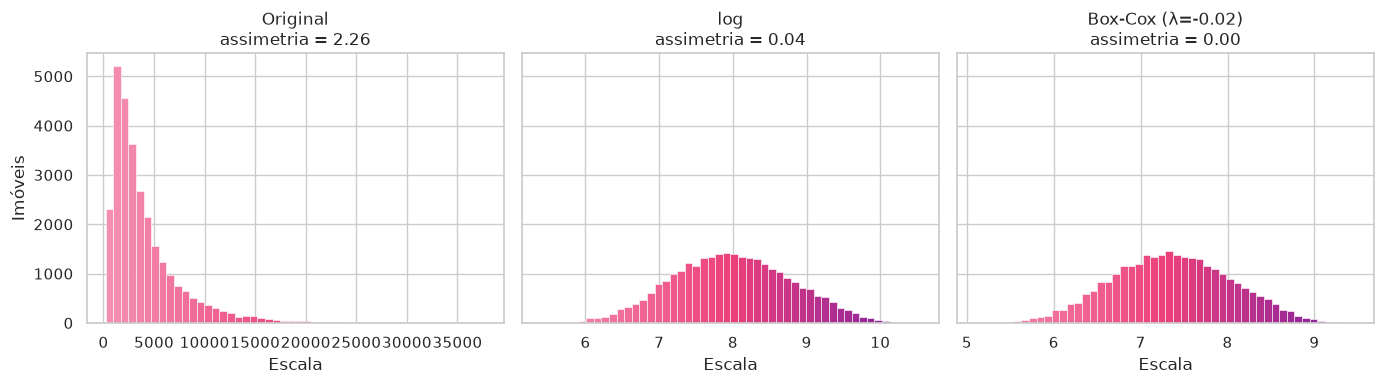

In [30]:
rent = imoveis_true.rent_amount

# Box-Cox devolve os valores transformados e o λ escolhido
boxcox_rent, boxcox_lambda = stats.boxcox(rent)

rent_transformed = {
    "Original": rent,
    "log": np.log(rent),
    f"Box-Cox (λ={boxcox_lambda:.2f})": boxcox_rent,
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, rent_transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color=ROSA)
    pintar_degrade(ax)
    ax.set(title=f"{label}\nassimetria = {stats.skew(values):.2f}", xlabel="Escala", ylabel="Imóveis")

plt.tight_layout()
plt.show()

> Análise: Agora o formato do histograma mudou de verdade: a assimetria caiu bastante em relação ao original. O Box-Cox escolheu um λ perto de zero, e λ = 0 é exatamente o logaritmo, então os dois dão praticamente o mesmo resultado. O log é preferível por ser mais simples de explicar: na escala log, ir de R$ 1.000 para R$ 2.000 é o mesmo salto que ir de R$ 10.000 para R$ 20.000.

### 7.1 Distância com zeros

A distância até o transporte pode ser zero, e log de zero não existe. Por isso comparo duas opções que aceitam zero: `log1p`, que calcula log(1 + x), e Yeo-Johnson.

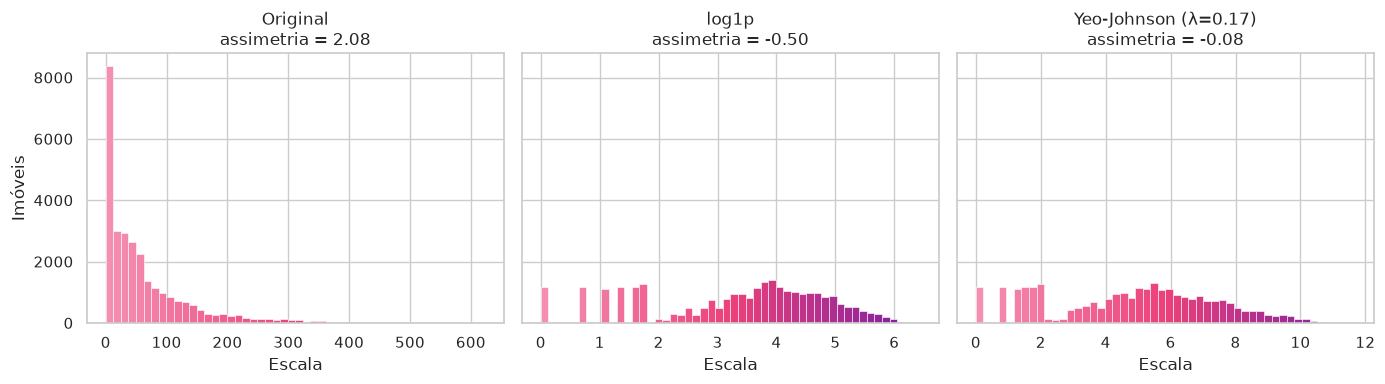

In [31]:
transit = imoveis_true.transit_distance_min

pt = PowerTransformer(method="yeo-johnson", standardize=False)
transit_yj = pt.fit_transform(imoveis_true[["transit_distance_min"]]).ravel()

transformed = {
    "Original": transit,
    "log1p": np.log1p(transit),  # log(1 + x), aceita zero
    f"Yeo-Johnson (λ={pt.lambdas_[0]:.2f})": transit_yj,
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color=ROSA)
    pintar_degrade(ax)
    ax.set(title=f"{label}\nassimetria = {stats.skew(values):.2f}", xlabel="Escala", ylabel="Imóveis")

plt.tight_layout()
plt.show()

> Análise: O `log1p` funciona com zero, mas aqui exagera: comprime tanto a cauda que a distribuição fica torta para o outro lado. O Yeo-Johnson calcula o próprio λ a partir dos dados e faz uma transformação mais suave, deixando a distância mais equilibrada.

**Resumo:** valores positivos combinam com log ou Box-Cox; com zeros, log1p ou Yeo-Johnson. Quanto mais "automática" a transformação, menos direta é a interpretação.